# **Genomic analysis of malaria vectors in The Gambia**

### **Carboxylesterase loci data exploration**

- In this notebook, we explore CNV in the COE loci following the detection of signal of selection in *Anopheles arabiensis* from the coast of Gambia

In [ ]:
import os
import malariagen_data
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import bokeh.io as bkio
bkio.output_notebook()

Loading BokehJS ...

In [ ]:
ag3 = malariagen_data.Ag3(pre=True)
ag3

<MalariaGEN Ag3 API client>
Storage URL             : gs://vo_agam_release_master_us_central1
Data releases available : 3.0, 3.1, 3.10, 3.11, 3.12, 3.13, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9
Results cache           : None
Cohorts analysis        : 20240717
AIM analysis            : 20220528
Site filters analysis   : dt_20200416
Software version        : malariagen_data 10.2.0
Client location         : Iowa, United States (Google Cloud us-central1)
---
Please note that data are subject to terms of use,
for more information see https://www.malariagen.net/data
or contact support@malariagen.net. For API documentation see 
https://malariagen.github.io/malariagen-data-python/v10.2.0/Ag3.html

In [ ]:
gambia_sample_query = "country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160'"

In [ ]:
# access metadata
df_samples_gambia = ag3.sample_metadata(sample_query=gambia_sample_query)
df_samples_gambia

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47721-6366STDY9854330,C1161,Kevin Opondo,"Gambia, The",Jareng,2019,9,13.620,-15.190,F,...,Janjanbureh,GM-M,Niamina East,coluzzii,GM-M_colu_2019,GM-M_colu_2019_09,GM-M_colu_2019_Q3,GM-M_Niamina-East_colu_2019,GM-M_Niamina-East_colu_2019_09,GM-M_Niamina-East_colu_2019_Q3
1,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
2,VBS47724-6366STDY9854333,C2526,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
3,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
4,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
656,AG0312-C,I-14,Charles Godfray,"Gambia, The",Wali Kunda,2012,10,13.567,-14.917,F,...,Janjanbureh,GM-M,Lower Fuladu West,coluzzii,GM-M_colu_2012,GM-M_colu_2012_10,GM-M_colu_2012_Q4,GM-M_Lower-Fuladu-West_colu_2012,GM-M_Lower-Fuladu-West_colu_2012_10,GM-M_Lower-Fuladu-West_colu_2012_Q4
657,AG0316-C,I-18,Charles Godfray,"Gambia, The",Wali Kunda,2012,10,13.567,-14.917,F,...,Janjanbureh,GM-M,Lower Fuladu West,coluzzii,GM-M_colu_2012,GM-M_colu_2012_10,GM-M_colu_2012_Q4,GM-M_Lower-Fuladu-West_colu_2012,GM-M_Lower-Fuladu-West_colu_2012_10,GM-M_Lower-Fuladu-West_colu_2012_Q4
658,AG0303-C,O-504,Charles Godfray,"Gambia, The",Wali Kunda,2012,10,13.567,-14.917,F,...,Janjanbureh,GM-M,Lower Fuladu West,coluzzii,GM-M_colu_2012,GM-M_colu_2012_10,GM-M_colu_2012_Q4,GM-M_Lower-Fuladu-West_colu_2012,GM-M_Lower-Fuladu-West_colu_2012_10,GM-M_Lower-Fuladu-West_colu_2012_Q4
659,AG0301-C,O-494,Charles Godfray,"Gambia, The",Wali Kunda,2012,10,13.567,-14.917,F,...,Janjanbureh,GM-M,Lower Fuladu West,coluzzii,GM-M_colu_2012,GM-M_colu_2012_10,GM-M_colu_2012_Q4,GM-M_Lower-Fuladu-West_colu_2012,GM-M_Lower-Fuladu-West_colu_2012_10,GM-M_Lower-Fuladu-West_colu_2012_Q4


In [ ]:
df_sample_sets = ag3.sample_sets(release=["3.0", "3.5"])
df_sample_sets

,sample_set,sample_count,study_id,study_url,terms_of_use_expiry_date,terms_of_use_url,release
0,AG1000G-AO,81,AG1000G-AO,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
1,AG1000G-BF-A,181,AG1000G-BF-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
2,AG1000G-BF-B,102,AG1000G-BF-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
3,AG1000G-BF-C,13,AG1000G-BF-2,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
4,AG1000G-CD,76,AG1000G-CD,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
5,AG1000G-CF,73,AG1000G-CF,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
6,AG1000G-CI,80,AG1000G-CI,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
7,AG1000G-CM-A,303,AG1000G-CM-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
8,AG1000G-CM-B,97,AG1000G-CM-2,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
9,AG1000G-CM-C,44,AG1000G-CM-3,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0


In [ ]:
df_samples_gambia.columns

Index(['sample_id', 'partner_sample_id', 'contributor', 'country', 'location',
       'year', 'month', 'latitude', 'longitude', 'sex_call', 'sample_set',
       'release', 'quarter', 'study_id', 'study_url', 'mean_cov', 'median_cov',
       'modal_cov', 'mean_cov_2L', 'median_cov_2L', 'mode_cov_2L',
       'mean_cov_2R', 'median_cov_2R', 'mode_cov_2R', 'mean_cov_3L',
       'median_cov_3L', 'mode_cov_3L', 'mean_cov_3R', 'median_cov_3R',
       'mode_cov_3R', 'mean_cov_X', 'median_cov_X', 'mode_cov_X',
       'frac_gen_cov', 'divergence', 'contam_pct', 'contam_LLR',
       'aim_species_fraction_arab', 'aim_species_fraction_colu',
       'aim_species_fraction_colu_no2l', 'aim_species_gambcolu_arabiensis',
       'aim_species_gambiae_coluzzii', 'aim_species', 'country_iso',
       'admin1_name', 'admin1_iso', 'admin2_name', 'taxon',
       'cohort_admin1_year', 'cohort_admin1_month', 'cohort_admin1_quarter',
       'cohort_admin2_year', 'cohort_admin2_month', 'cohort_admin2_quarter'],
   

In [ ]:
df_samples_gambia.query("sample_set == '1272-VO-GM-OPONDO-VMF00160' and taxon == 'arabiensis'")

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
1,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
3,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
4,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
6,VBS47729-6366STDY9854338,C2710,Kevin Opondo,"Gambia, The",Boiram,2019,10,13.503,-14.926,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_10,GM-M_arab_2019_Q4,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_10,GM-M_Lower-Fuladu-West_arab_2019_Q4
7,VBS47731-6366STDY9854340,C2524,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,VBS48167-6366STDY9854768,W1491,Kevin Opondo,"Gambia, The",Essau,2019,10,13.481,-16.515,F,...,Kerewan,GM-N,Lower Niumi,arabiensis,GM-N_arab_2019,GM-N_arab_2019_10,GM-N_arab_2019_Q4,GM-N_Lower-Niumi_arab_2019,GM-N_Lower-Niumi_arab_2019_10,GM-N_Lower-Niumi_arab_2019_Q4
376,VBS48171-6366STDY9854772,W2321,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.290,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
378,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
379,VBS48174-6366STDY9854775,W1168,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3


**CNV HMM data**

Sample sets
- AG1000G-GM-A
- AG1000G-GM-B
- AG1000G-GM-C
- 1272-VO-GM-OPONDO-VMF00160

In [ ]:
# sample with Dup14 only
df_samples_gambia.query("sample_id == 'VBS48045-6366STDY9854645'")

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
278,VBS48045-6366STDY9854645,C3531,Kevin Opondo,"Gambia, The",Saruja,2019,11,13.551,-14.913,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_11,GM-M_arab_2019_Q4,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_11,GM-M_Lower-Fuladu-West_arab_2019_Q4


In [ ]:
ag3.plot_cnv_hmm_coverage(sample='VBS48045-6366STDY9854645', sample_set='1272-VO-GM-OPONDO-VMF00160', region=coe_region_extended)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

In [ ]:
coe_region = "2L:37,233,000-37,330,000"
coe_region_extended = "2L:37,217,000-37,335,000"

In [ ]:
hmm = ag3.cnv_hmm(region="2L", sample_sets="1272-VO-GM-OPONDO-VMF00160").set_index(samples="sample_id")
hmm

<xarray.Dataset> Size: 244MB
Dimensions:                   (variants: 164548, samples: 164)
Coordinates:
    variant_position          (variants) int32 658kB dask.array<chunksize=(65536,), meta=np.ndarray>
    variant_end               (variants) int32 658kB dask.array<chunksize=(65536,), meta=np.ndarray>
    variant_contig            (variants) uint8 165kB dask.array<chunksize=(164548,), meta=np.ndarray>
  * samples                   (samples) object 1kB 'VBS47724-6366STDY9854333'...
Dimensions without coordinates: variants
Data variables:
    call_CN                   (variants, samples) int8 27MB dask.array<chunksize=(65536, 16), meta=np.ndarray>
    call_RawCov               (variants, samples) int32 108MB dask.array<chunksize=(65536, 16), meta=np.ndarray>
    call_NormCov              (variants, samples) float32 108MB dask.array<chunksize=(65536, 16), meta=np.ndarray>
    sample_coverage_variance  (samples) float32 656B dask.array<chunksize=(164,), meta=np.ndarray>
    sample_is_high_variance   (samples) bool 164B dask.array<chunksize=(164,), meta=np.ndarray>
Attributes:
    contigs:  ('2R', '2L', '3R', '3L', 'X')

In [ ]:
# samples from Jeshwang

df_jw = df_samples_gambia.query("sample_set == '1272-VO-GM-OPONDO-VMF00160' and taxon == 'arabiensis' and admin2_name == 'Jeshwang'")
df_jw

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
124,VBS47876-6366STDY9854479,W2544,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
126,VBS47879-6366STDY9854481,W0672,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
127,VBS47880-6366STDY9854482,W2502,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
128,VBS47881-6366STDY9854483,W1953,Kevin Opondo,"Gambia, The",Ebotown,2019,9,13.438,-16.674,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
129,VBS47882-6366STDY9854484,W0593,Kevin Opondo,"Gambia, The",Ebotown,2019,9,13.438,-16.674,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
362,VBS48147-6366STDY9854749,W2195,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
364,VBS48149-6366STDY9854751,W2835,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
370,VBS48158-6366STDY9854760,W0659,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
378,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3


In [ ]:
sample_names_jw = ['VBS47876-6366STDY9854479', 'VBS47881-6366STDY9854483', 'VBS48147-6366STDY9854749', 'VBS48158-6366STDY9854760', 'VBS48174-6366STDY9854775']

In [ ]:
for s in sample_names_jw:
    ag3.plot_cnv_hmm_coverage(s, sample_set='1272-VO-GM-OPONDO-VMF00160', region=coe_region_extended)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

In [ ]:
# samples from Kombo central
df_kc = df_samples_gambia.query("sample_set == '1272-VO-GM-OPONDO-VMF00160' and taxon == 'arabiensis' and admin2_name == 'Kombo Central'")
df_kc

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
125,VBS47878-6366STDY9854480,W2335,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
130,VBS47884-6366STDY9854485,W2439,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
135,VBS47890-6366STDY9854490,W1817,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
144,VBS47901-6366STDY9854499,W1821,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
147,VBS47904-6366STDY9854502,W2355,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
149,VBS47906-6366STDY9854504,W1692,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
153,VBS47910-6366STDY9854508,W2430,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
157,VBS47914-6366STDY9854512,W2145,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
164,VBS47921-6366STDY9854521,W1723,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
165,VBS47922-6366STDY9854522,W2347,Kevin Opondo,"Gambia, The",Brikama,2019,9,13.29,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3


In [ ]:
sample_names_kc = ['VBS47878-6366STDY9854480', 'VBS47906-6366STDY9854504', 'VBS47975-6366STDY9854573', 'VBS48154-6366STDY9854756', 'VBS48175-6366STDY9854776']

In [ ]:
for s in sample_names_kc:
    ag3.plot_cnv_hmm_coverage(s, sample_set='1272-VO-GM-OPONDO-VMF00160', region=coe_region_extended)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

In [ ]:
# samples from Basse
df_bs = df_samples_gambia.query("sample_set == '1272-VO-GM-OPONDO-VMF00160' and taxon == 'arabiensis' and admin2_name == 'Basse'")
df_bs

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
56,VBS47793-6366STDY9854400,E0120,Kevin Opondo,"Gambia, The",Kaba Kamma,2019,9,13.305,-14.207,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
59,VBS47796-6366STDY9854403,E3092,Kevin Opondo,"Gambia, The",Santo Su,2019,9,13.307,-14.220,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
71,VBS47814-6366STDY9854418,E2642,Kevin Opondo,"Gambia, The",Santo Su,2019,9,13.307,-14.220,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
83,VBS47826-6366STDY9854432,E0858,Kevin Opondo,"Gambia, The",Sabi,2019,9,13.237,-14.196,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
86,VBS47829-6366STDY9854435,E0094,Kevin Opondo,"Gambia, The",Kaba Kamma,2019,9,13.305,-14.207,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
95,VBS47840-6366STDY9854445,E2474,Kevin Opondo,"Gambia, The",Sabi,2019,9,13.237,-14.196,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
97,VBS47842-6366STDY9854447,E0804,Kevin Opondo,"Gambia, The",Sabi,2019,9,13.237,-14.196,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
99,VBS47844-6366STDY9854449,E0084,Kevin Opondo,"Gambia, The",Kaba Kamma,2019,9,13.305,-14.207,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
101,VBS47846-6366STDY9854451,E0775,Kevin Opondo,"Gambia, The",Sabi,2019,9,13.237,-14.196,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3
107,VBS47852-6366STDY9854457,E2591,Kevin Opondo,"Gambia, The",Santo Su,2019,9,13.307,-14.220,F,...,Basse,GM-U,Basse,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Basse_arab_2019,GM-U_Basse_arab_2019_09,GM-U_Basse_arab_2019_Q3


In [ ]:
sample_names_bs = ['VBS47793-6366STDY9854400', 'VBS47840-6366STDY9854445', 'VBS47852-6366STDY9854457', 'VBS48063-6366STDY9854663', 'VBS48100-6366STDY9854700']

In [ ]:
for s in sample_names_bs:
    ag3.plot_cnv_hmm_coverage(s, sample_set='1272-VO-GM-OPONDO-VMF00160', region=coe_region_extended)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

In [ ]:
# samples from Jimara
df_ji = df_samples_gambia.query("sample_set == '1272-VO-GM-OPONDO-VMF00160' and taxon == 'arabiensis' and admin2_name == 'Jimara'")
df_ji

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
53,VBS47790-6366STDY9854397,E2391,Kevin Opondo,"Gambia, The",Gambisara,2019,9,13.236,-14.310,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_09,GM-U_Jimara_arab_2019_Q3
55,VBS47792-6366STDY9854399,E1699,Kevin Opondo,"Gambia, The",Damba kunda Kuta,2019,10,13.260,-14.268,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_10,GM-U_arab_2019_Q4,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_10,GM-U_Jimara_arab_2019_Q4
57,VBS47794-6366STDY9854401,E0239,Kevin Opondo,"Gambia, The",Sotuma sere,2019,9,13.294,-14.320,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_09,GM-U_Jimara_arab_2019_Q3
65,VBS47806-6366STDY9854410,E2894,Kevin Opondo,"Gambia, The",Gambisara,2019,9,13.236,-14.310,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_09,GM-U_Jimara_arab_2019_Q3
66,VBS47807-6366STDY9854411,E0277,Kevin Opondo,"Gambia, The",Sotuma sere,2019,9,13.294,-14.320,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_09,GM-U_Jimara_arab_2019_Q3
68,VBS47809-6366STDY9854413,E1220,Kevin Opondo,"Gambia, The",Kossemar,2019,9,13.331,-14.376,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_09,GM-U_Jimara_arab_2019_Q3
69,VBS47810-6366STDY9854414,E0463,Kevin Opondo,"Gambia, The",Damba kunda Kuta,2019,10,13.260,-14.268,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_10,GM-U_arab_2019_Q4,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_10,GM-U_Jimara_arab_2019_Q4
74,VBS47817-6366STDY9854421,E3984,Kevin Opondo,"Gambia, The",Gambisara,2019,9,13.236,-14.310,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_09,GM-U_Jimara_arab_2019_Q3
80,VBS47823-6366STDY9854429,E0241,Kevin Opondo,"Gambia, The",Sotuma sere,2019,9,13.294,-14.320,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_09,GM-U_Jimara_arab_2019_Q3
81,VBS47824-6366STDY9854430,E1001,Kevin Opondo,"Gambia, The",Kossemar,2019,9,13.331,-14.376,F,...,Basse,GM-U,Jimara,arabiensis,GM-U_arab_2019,GM-U_arab_2019_09,GM-U_arab_2019_Q3,GM-U_Jimara_arab_2019,GM-U_Jimara_arab_2019_09,GM-U_Jimara_arab_2019_Q3


In [ ]:
sample_names_ji = ['VBS47790-6366STDY9854397', 'VBS47807-6366STDY9854411', 'VBS48061-6366STDY9854661', 'VBS48114-6366STDY9854716', 'VBS48135-6366STDY9854737']

In [ ]:
for s in sample_names_ji:
    ag3.plot_cnv_hmm_coverage(s, sample_set='1272-VO-GM-OPONDO-VMF00160', region=coe_region_extended)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:747: UserWarning: found multiple competing value

In [ ]:
ag3.plot_cnv_hmm_heatmap(
    region=coe_region_extended,
    sample_query="taxon == 'arabiensis'",
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    row_height=2
);

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:950: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bklay.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/cnv_data.py:950: UserWarning: found multiple competing value

#### **Organophosphate resistance markers (Ace1)**

In [ ]:
ace1_aa_freqs_df = ag3.aa_allele_frequencies(
    transcript="AGAP001356-RA",
    cohorts="admin2_year",
    sample_query=gambia_sample_query
)

ace1_aa_freqs_df

Compute allele frequencies:   0%|          | 0/14 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/6837 [00:00<?, ?it/s]

,,,frq_GM-L_Kiang-West_colu_2006,frq_GM-M_Lower-Fuladu-West_arab_2019,frq_GM-M_Lower-Fuladu-West_colu_2012,frq_GM-M_Lower-Fuladu-West_colu_2019,frq_GM-M_Niamina-East_arab_2019,frq_GM-M_Upper-Fuladu-West_arab_2019,frq_GM-N_Central-Badibu_gcx1_2011,frq_GM-N_Lower-Niumi_arab_2019,frq_GM-U_Basse_arab_2019,frq_GM-U_Jimara_arab_2019,...,transcript,aa_pos,ref_allele,ref_aa,alt_aa,effect,impact,alt_allele,max_af,label
aa_change,contig,position,,,,,,,,,,,,,,,,,,,,,
G5E,2R,3489226,0.0,0.00,0.000000,0.041667,0.0,0.0,0.000000,0.0,0.000000,0.000000,...,AGAP001356-RA,5.0,G,G,E,NON_SYNONYMOUS_CODING,MODERATE,A,0.041667,"G5E (2R:3,489,226 G>A)"
G9C,2R,3489237,0.0,0.00,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,...,AGAP001356-RA,9.0,G,G,C,NON_SYNONYMOUS_CODING,MODERATE,T,0.017857,"G9C (2R:3,489,237 G>T)"
R10S,2R,3489242,0.0,0.00,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.013514,...,AGAP001356-RA,10.0,A,R,S,NON_SYNONYMOUS_CODING,MODERATE,T,0.013514,"R10S (2R:3,489,242 A>T)"
R12W,2R,3489246,0.0,0.00,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.013514,...,AGAP001356-RA,12.0,C,R,W,NON_SYNONYMOUS_CODING,MODERATE,T,0.013514,"R12W (2R:3,489,246 C>T)"
R16L,2R,3489259,0.0,0.00,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.017857,0.000000,...,AGAP001356-RA,16.0,G,R,L,NON_SYNONYMOUS_CODING,MODERATE,T,0.017857,"R16L (2R:3,489,259 G>T)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A731G,2R,3493766,0.0,0.01,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,...,AGAP001356-RA,731.0,C,A,G,NON_SYNONYMOUS_CODING,MODERATE,G,0.010000,"A731G (2R:3,493,766 C>G)"
A731V,2R,3493766,0.0,0.00,0.005814,0.041667,0.0,0.0,0.007463,0.0,0.000000,0.000000,...,AGAP001356-RA,731.0,C,A,V,NON_SYNONYMOUS_CODING,MODERATE,T,0.041667,"A731V (2R:3,493,766 C>T)"
V733I,2R,3493771,0.0,0.00,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.013514,...,AGAP001356-RA,733.0,G,V,I,NON_SYNONYMOUS_CODING,MODERATE,A,0.013514,"V733I (2R:3,493,771 G>A)"


In [ ]:
ace1_aa_filt_df = ace1_aa_freqs_df.query("max_af >= 0.05")
ace1_aa_filt_df

,,,frq_GM-L_Kiang-West_gcx2_2006,frq_GM-M_Lower-Fuladu-West_arab_2019,frq_GM-M_Lower-Fuladu-West_gcx2_2012,frq_GM-M_Lower-Fuladu-West_gcx2_2019,frq_GM-M_Niamina-East_arab_2019,frq_GM-M_Upper-Fuladu-West_arab_2019,frq_GM-N_Central-Badibu_gcx1_2011,frq_GM-N_Lower-Niumi_arab_2019,frq_GM-U_Basse_arab_2019,frq_GM-U_Jimara_arab_2019,...,transcript,aa_pos,ref_allele,ref_aa,alt_aa,effect,impact,alt_allele,max_af,label
aa_change,contig,position,,,,,,,,,,,,,,,,,,,,,
L20P,2R,3489271,0.000000,0.000000,0.000000,0.000,0.05,0.000000,0.000000,0.000000,0.000000,0.000000,...,AGAP001356-RA,20.0,T,L,P,NON_SYNONYMOUS_CODING,MODERATE,C,0.050000,"L20P (2R:3,489,271 T>C)"
V25L,2R,3489285,0.000000,0.000000,0.000000,0.000,0.00,0.000000,0.000000,0.038462,0.000000,0.000000,...,AGAP001356-RA,25.0,G,V,L,NON_SYNONYMOUS_CODING,MODERATE,T,0.051948,"V25L (2R:3,489,285 G>T)"
F35S,2R,3489316,0.973684,1.000000,0.976744,1.000,1.00,1.000000,0.970588,1.000000,1.000000,1.000000,...,AGAP001356-RA,35.0,T,F,S,NON_SYNONYMOUS_CODING,MODERATE,C,1.000000,"F35S (2R:3,489,316 T>C)"
A65S,2R,3489405,0.315789,0.990000,0.363372,0.375,1.00,1.000000,0.455882,1.000000,1.000000,1.000000,...,AGAP001356-RA,65.0,G,A,S,NON_SYNONYMOUS_CODING,MODERATE,T,1.000000,"A65S (2R:3,489,405 G>T)"
S71Y,2R,3489424,0.000000,0.000000,0.000000,0.000,0.05,0.000000,0.000000,0.000000,0.000000,0.000000,...,AGAP001356-RA,71.0,C,S,Y,NON_SYNONYMOUS_CODING,MODERATE,A,0.050000,"S71Y (2R:3,489,424 C>A)"
R128L,2R,3491533,0.000000,0.000000,0.000000,0.000,0.05,0.000000,0.000000,0.000000,0.000000,0.000000,...,AGAP001356-RA,128.0,G,R,L,NON_SYNONYMOUS_CODING,MODERATE,T,0.050000,"R128L (2R:3,491,533 G>T)"
R148*,2R,3491592,0.000000,0.000000,0.000000,0.000,0.05,0.000000,0.000000,0.000000,0.000000,0.000000,...,AGAP001356-RA,148.0,C,R,*,STOP_GAINED,HIGH,T,0.050000,"R148* (2R:3,491,592 C>T)"
Q198K,2R,3491828,0.000000,0.000000,0.000000,0.000,0.05,0.000000,0.000000,0.000000,0.000000,0.000000,...,AGAP001356-RA,198.0,C,Q,K,NON_SYNONYMOUS_CODING,MODERATE,A,0.050000,"Q198K (2R:3,491,828 C>A)"
G241C,2R,3491957,0.000000,0.000000,0.000000,0.000,0.05,0.000000,0.000000,0.000000,0.000000,0.000000,...,AGAP001356-RA,241.0,G,G,C,NON_SYNONYMOUS_CODING,MODERATE,T,0.050000,"G241C (2R:3,491,957 G>T)"


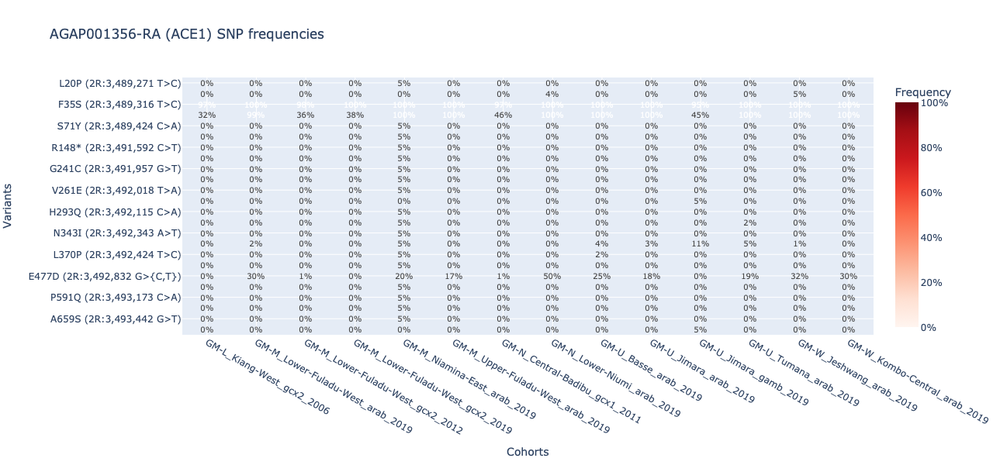

In [ ]:
ag3.plot_frequencies_heatmap(ace1_aa_filt_df, height=600, width=1000)

In [ ]:
ag3.plot_cnv_hmm_heatmap(
    region='2R:3,300,000-4,000,000',
    sample_query='taxon == "arabiensis"',
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    row_height=2
);

In [ ]:
ace1_cnv_freqs_df = ag3.gene_cnv_frequencies(
    region="2R:3,483,099-3,497,400",
    cohorts="admin2_year",
    sample_query="country == 'Gambia, The' and taxon == 'arabiensis'",
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
)
ace1_cnv_freqs_df

Load CNV HMM data:   0%|          | 0/56 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/1 [00:00<?, ?it/s]

,,,gene_strand,gene_description,contig,start,end,frq_GM-M_Lower-Fuladu-West_arab_2019,frq_GM-U_Basse_arab_2019,frq_GM-U_Jimara_arab_2019,frq_GM-W_Jeshwang_arab_2019,frq_GM-W_Kombo-Central_arab_2019,max_af,windows,label
gene_id,gene_name,cnv_type,,,,,,,,,,,,,
